In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import time
import os

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.model_selection import train_test_split

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)
import sys
sys.path.append("../src/genetic_algorithm")
from genetic_algorithm import genetic_algorithm
from representation import profondeur, nombre_feuilles

sns.set_theme(style="whitegrid")

os.makedirs("../results/graphs", exist_ok=True)
os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/best_tree", exist_ok=True)

Chargement des données

In [2]:
X_train = pd.read_csv("../dataset/processed/X_train.csv")
X_test = pd.read_csv("../dataset/processed/X_test.csv")

y_train = pd.read_csv("../dataset/processed/y_train.csv").squeeze()
y_test = pd.read_csv("../dataset/processed/y_test.csv").squeeze()

print("Dimensions X_train :", X_train.shape)
print("Dimensions X_test :", X_test.shape)

print("Dimensions y_train :", y_train.shape)
print("Dimensions y_test :", y_test.shape)

Dimensions X_train : (226980, 30)
Dimensions X_test : (56746, 30)
Dimensions y_train : (226980,)
Dimensions y_test : (56746,)


Modèle CART (Decision Tree)

In [3]:
dt_model = DecisionTreeClassifier(
    random_state=42,
    class_weight="balanced"
)

start_time = time.time()

dt_model.fit(X_train, y_train)

dt_time = time.time() - start_time

y_pred_dt = dt_model.predict(X_test)

print("Decision Tree entraîné avec succès !")
print("Temps d'entraînement :", round(dt_time, 3), "secondes")

Decision Tree entraîné avec succès !
Temps d'entraînement : 19.176 secondes


Évaluation du modèle CART

In [4]:
dt_accuracy = accuracy_score(y_test, y_pred_dt)
dt_precision = precision_score(y_test, y_pred_dt, zero_division=0)
dt_recall = recall_score(y_test, y_pred_dt, zero_division=0)
dt_f1 = f1_score(y_test, y_pred_dt, zero_division=0)

print("RESULTATS CART ")

print("Accuracy  :", round(dt_accuracy, 4))
print("Precision :", round(dt_precision, 4))
print("Recall    :", round(dt_recall, 4))
print("F1-score  :", round(dt_f1, 4))

RESULTATS CART 
Accuracy  : 0.999
Precision : 0.7349
Recall    : 0.6421
F1-score  : 0.6854


Matrice de confusion — CART

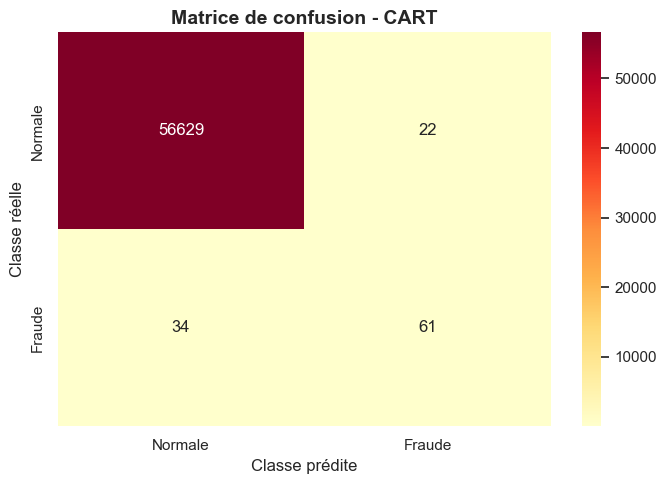

In [5]:
cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="YlOrRd",
    xticklabels=["Normale", "Fraude"],
    yticklabels=["Normale", "Fraude"]
)

plt.title("Matrice de confusion - CART",
          fontsize=14, fontweight="bold")

plt.xlabel("Classe prédite")
plt.ylabel("Classe réelle")

plt.tight_layout()
plt.savefig("../results/graphs/matrice_cart.png", dpi=150)
plt.show()

Modèle Random Forest

In [6]:
rf_model = RandomForestClassifier(
    n_estimators=100,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

start_time = time.time()

rf_model.fit(X_train, y_train)

rf_time = time.time() - start_time

y_pred_rf = rf_model.predict(X_test)

print("RANDOM FOREST ")

print("Accuracy :", accuracy_score(y_test, y_pred_rf))
print("Precision :", precision_score(y_test, y_pred_rf, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_rf, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_rf, zero_division=0))
print("Temps d'entraînement :", round(rf_time, 2), "secondes")

RANDOM FOREST 
Accuracy : 0.9994713283755683
Precision : 0.9710144927536232
Recall : 0.7052631578947368
F1-score : 0.8170731707317073
Temps d'entraînement : 104.39 secondes


Modèle Gradient Boosting

In [7]:
gb_model = GradientBoostingClassifier(
    n_estimators=30,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

start_time = time.time()

gb_model.fit(X_train, y_train)

gb_time = time.time() - start_time

y_pred_gb = gb_model.predict(X_test)

print("GRADIENT BOOSTING ")

print("Accuracy :", accuracy_score(y_test, y_pred_gb))
print("Precision :", precision_score(y_test, y_pred_gb, zero_division=0))
print("Recall :", recall_score(y_test, y_pred_gb, zero_division=0))
print("F1-score :", f1_score(y_test, y_pred_gb, zero_division=0))
print("Temps d'entraînement :", round(gb_time, 2), "secondes")

GRADIENT BOOSTING 
Accuracy : 0.9992069925633524
Precision : 0.8676470588235294
Recall : 0.6210526315789474
F1-score : 0.7239263803680982
Temps d'entraînement : 171.56 secondes


Préparation des données pour l'algorithme génétique

In [8]:
X_ga_train, X_ga_val, y_ga_train, y_ga_val = train_test_split(
    X_train,
    y_train,
    test_size=0.2,
    random_state=42,
    stratify=y_train
)

# Indices des deux classes
indices_fraudes = y_ga_val[y_ga_val == 1].index

indices_normaux = y_ga_val[y_ga_val == 0].sample(
    n=len(indices_fraudes),
    random_state=42
).index

# Combiner les indices
indices = list(indices_fraudes) + list(indices_normaux)

# Validation équilibrée
X_ga_val = X_ga_val.loc[indices]
y_ga_val = y_ga_val.loc[indices]

print(" DONNEES POUR AG ")
print("X_ga_train :", X_ga_train.shape)
print("X_ga_val :", X_ga_val.shape)

print("\nRépartition de la validation :")
print(y_ga_val.value_counts())

 DONNEES POUR AG 
X_ga_train : (181584, 30)
X_ga_val : (152, 30)

Répartition de la validation :
Class
1    76
0    76
Name: count, dtype: int64


Exécution de l'algorithme génétique

In [9]:
import sys
sys.path.append("../src/genetic_algorithm")
from genetic_algorithm import genetic_algorithm
from representation import profondeur, nombre_feuilles
start_time = time.time()
meilleur_arbre, historique = genetic_algorithm(
    X_train=X_ga_train,
    y_train=y_ga_train,
    X_val=X_ga_val,
    y_val=y_ga_val,
    population_size=20,
    generations=10,
    max_depth=5,
    taux_mutation=0.2,
    taux_croisement=0.8,
    methode_selection="tournoi"
)

ga_time = time.time() - start_time

print("\n MEILLEUR ARBRE GENETIQUE")

print("Profondeur :", profondeur(meilleur_arbre))
print("Nombre de feuilles :", nombre_feuilles(meilleur_arbre))
print("Temps d'exécution :", round(ga_time, 2), "secondes")

Generation 1 | Meilleure fitness : 0.48688 | Profondeur : 1
Generation 2 | Meilleure fitness : 0.55426 | Profondeur : 2
Generation 3 | Meilleure fitness : 0.55426 | Profondeur : 2
Generation 4 | Meilleure fitness : 0.75329 | Profondeur : 5
Generation 5 | Meilleure fitness : 0.75329 | Profondeur : 5
Generation 6 | Meilleure fitness : 0.81094 | Profondeur : 5
Generation 7 | Meilleure fitness : 0.81094 | Profondeur : 5
Generation 8 | Meilleure fitness : 0.82406 | Profondeur : 4
Generation 9 | Meilleure fitness : 0.83882 | Profondeur : 5
Generation 10 | Meilleure fitness : 0.83882 | Profondeur : 5

 MEILLEUR ARBRE GENETIQUE
Profondeur : 5
Nombre de feuilles : 8
Temps d'exécution : 4.7 secondes


Évaluation de l'arbre génétique

In [10]:
y_pred_ga = [
    meilleur_arbre.predict(row)
    for row in X_test.to_numpy()
]

ga_accuracy = accuracy_score(y_test, y_pred_ga)
ga_precision = precision_score(y_test, y_pred_ga, zero_division=0)
ga_recall = recall_score(y_test, y_pred_ga, zero_division=0)
ga_f1 = f1_score(y_test, y_pred_ga, zero_division=0)

print(" RESULTATS ALGORITHME GENETIQUE")

print("Accuracy  :", round(ga_accuracy, 4))
print("Precision :", round(ga_precision, 4))
print("Recall    :", round(ga_recall, 4))
print("F1-score  :", round(ga_f1, 4))

print("\nMatrice de confusion :")
print(confusion_matrix(y_test, y_pred_ga))

print("\nRapport de classification :")
print(classification_report(
    y_test,
    y_pred_ga,
    zero_division=0
))

 RESULTATS ALGORITHME GENETIQUE
Accuracy  : 0.9737
Precision : 0.0474
Recall    : 0.7684
F1-score  : 0.0892

Matrice de confusion :
[[55183  1468]
 [   22    73]]

Rapport de classification :
              precision    recall  f1-score   support

           0       1.00      0.97      0.99     56651
           1       0.05      0.77      0.09        95

    accuracy                           0.97     56746
   macro avg       0.52      0.87      0.54     56746
weighted avg       1.00      0.97      0.99     56746



Matrice de confusion — AG

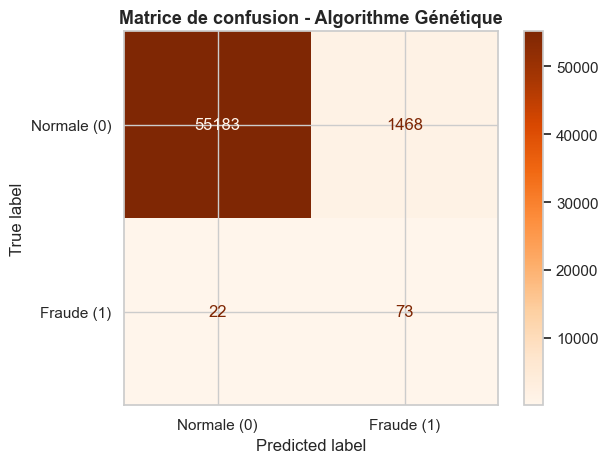

In [11]:
cm_ga = confusion_matrix(y_test, y_pred_ga)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_ga,
    display_labels=["Normale (0)", "Fraude (1)"]
)

disp.plot(cmap="Oranges", values_format="d")

plt.title("Matrice de confusion - Algorithme Génétique",
          fontsize=13, fontweight="bold")

plt.tight_layout()
plt.savefig("../results/graphs/matrice_ag.png", dpi=150)
plt.show()

Affichage de l'arbre génétique

In [12]:
def afficher_arbre(arbre, niveau=0):

    espace = "  " * niveau

    if arbre.is_leaf():
        print(espace + "Feuille :", arbre.prediction)

    else:
        print(espace + "Feature :", X_train.columns[arbre.feature])
        print(espace + "Threshold :", round(arbre.threshold, 3))

        print(espace + "Gauche :")
        afficher_arbre(arbre.left, niveau + 1)

        print(espace + "Droite :")
        afficher_arbre(arbre.right, niveau + 1)


print(" STRUCTURE DE L'ARBRE GENETIQUE ")
afficher_arbre(meilleur_arbre)

 STRUCTURE DE L'ARBRE GENETIQUE 
Feature : V14
Threshold : -0.136
Gauche :
  Feature : V8
  Threshold : -0.872
  Gauche :
    Feuille : 1
  Droite :
    Feature : V14
    Threshold : -2.825
    Gauche :
      Feature : V20
      Threshold : -0.106
      Gauche :
        Feuille : 1
      Droite :
        Feuille : 1
    Droite :
      Feature : V8
      Threshold : -0.872
      Gauche :
        Feuille : 1
      Droite :
        Feature : V14
        Threshold : -2.825
        Gauche :
          Feuille : 0
        Droite :
          Feuille : 0
Droite :
  Feature : V22
  Threshold : -0.035
  Gauche :
    Feuille : 0
  Droite :
    Feuille : 0


Visualisation graphique de l'arbre génétique

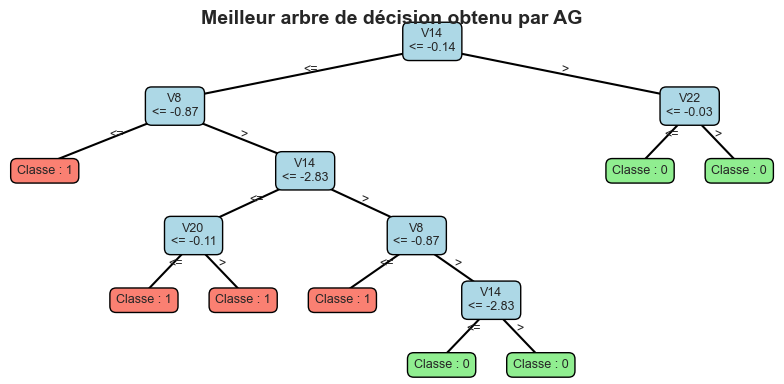

In [13]:
positions = {}
compteur = [0]


def calculer_positions(node, niveau=0):

    if node.is_leaf():
        x = compteur[0]
        compteur[0] += 1

    else:
        x_gauche = calculer_positions(node.left, niveau + 1)
        x_droite = calculer_positions(node.right, niveau + 1)

        x = (x_gauche + x_droite) / 2

    positions[id(node)] = (x, -niveau)

    return x


def dessiner_arbre(node):

    x, y = positions[id(node)]

    if node.is_leaf():

        texte = "Classe : " + str(node.prediction)

        couleur = (
            "lightgreen"
            if node.prediction == 0
            else "salmon"
        )

    else:

        nom_feature = X_train.columns[node.feature]

        texte = f"{nom_feature}\n<= {node.threshold:.2f}"

        couleur = "lightblue"

    plt.text(
        x, y, texte,
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.5",
            facecolor=couleur,
            edgecolor="black"
        ),
        fontsize=9
    )

    if not node.is_leaf():

        for enfant, etiquette in [
            (node.left, "<="),
            (node.right, ">")
        ]:

            x2, y2 = positions[id(enfant)]

            plt.plot(
                [x, x2],
                [y - 0.1, y2 + 0.1],
                color="black"
            )

            plt.text(
                (x + x2) / 2,
                (y + y2) / 2,
                etiquette,
                fontsize=9
            )

            dessiner_arbre(enfant)


calculer_positions(meilleur_arbre)

plt.figure(figsize=(8, 4))

dessiner_arbre(meilleur_arbre)

plt.title(
    "Meilleur arbre de décision obtenu par AG",
    fontsize=14,
    fontweight="bold"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "../results/graphs/arbre_genetique.png",
    dpi=150,
    bbox_inches="tight"
)

plt.show()

Courbe de convergence de l'AG

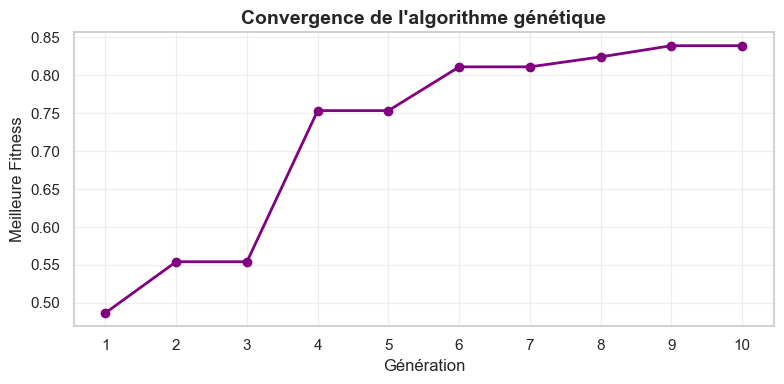

In [14]:
plt.figure(figsize=(8, 4))

plt.plot(
    range(1, len(historique) + 1),
    historique,
    marker="o",
    color="purple",
    linewidth=2
)

plt.title(
    "Convergence de l'algorithme génétique",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Génération")
plt.ylabel("Meilleure Fitness")

plt.xticks(range(1, len(historique) + 1))

plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig("../results/graphs/convergence_ag.png", dpi=150)

plt.show()

Comparaison des quatre modèles

In [15]:
comparaison = pd.DataFrame({

    "Modèle": [
        "CART",
        "Random Forest",
        "Gradient Boosting",
        "AG"
    ],

    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_gb),
        accuracy_score(y_test, y_pred_ga)
    ],

    "Precision": [
        precision_score(y_test, y_pred_dt, zero_division=0),
        precision_score(y_test, y_pred_rf, zero_division=0),
        precision_score(y_test, y_pred_gb, zero_division=0),
        precision_score(y_test, y_pred_ga, zero_division=0)
    ],

    "Recall": [
        recall_score(y_test, y_pred_dt, zero_division=0),
        recall_score(y_test, y_pred_rf, zero_division=0),
        recall_score(y_test, y_pred_gb, zero_division=0),
        recall_score(y_test, y_pred_ga, zero_division=0)
    ],

    "F1-score": [
        f1_score(y_test, y_pred_dt, zero_division=0),
        f1_score(y_test, y_pred_rf, zero_division=0),
        f1_score(y_test, y_pred_gb, zero_division=0),
        f1_score(y_test, y_pred_ga, zero_division=0)
    ],

    "Temps (s)": [
        dt_time,
        rf_time,
        gb_time,
        ga_time
    ]
})

print("COMPARAISON DES MODELES ")

display(comparaison.round(4))

COMPARAISON DES MODELES 


,Modèle,Accuracy,Precision,Recall,F1-score,Temps (s)
0,CART,0.9990,0.7349,0.6421,0.6854,19.1759
1,Random Forest,0.9995,0.9710,0.7053,0.8171,104.3864
2,Gradient Boosting,0.9992,0.8676,0.6211,0.7239,171.5607
3,AG,0.9737,0.0474,0.7684,0.0892,4.6998


Diagramme de comparaison des performances

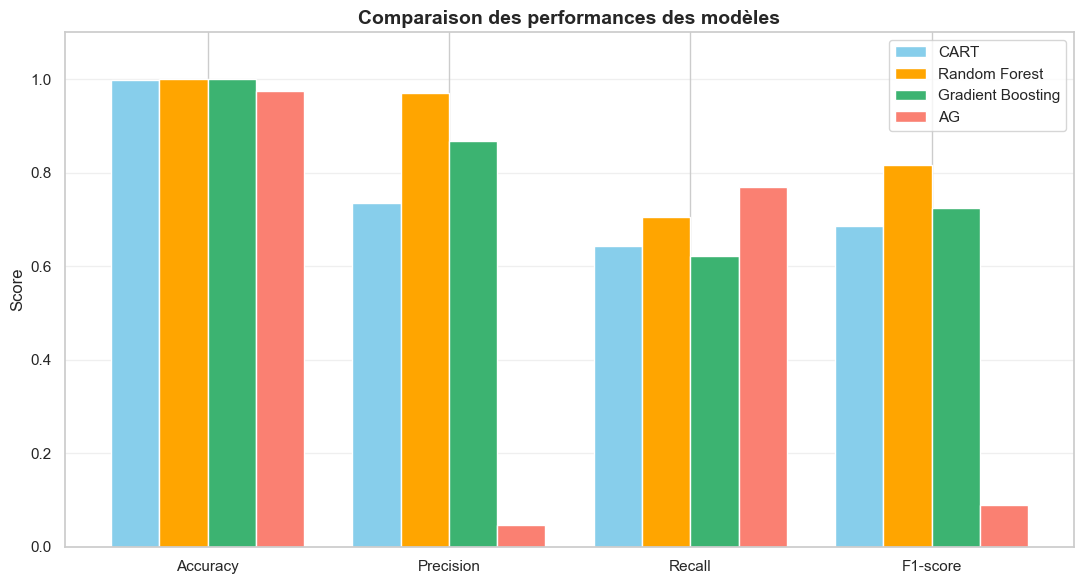

In [16]:
metriques = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-score"
]

x = np.arange(len(metriques))

largeur = 0.2

couleurs = [
    "skyblue",
    "orange",
    "mediumseagreen",
    "salmon"
]

modeles = [
    "CART",
    "Random Forest",
    "Gradient Boosting",
    "AG"
]

plt.figure(figsize=(11, 6))

for i, modele in enumerate(modeles):

    plt.bar(
        x + (i - 1.5) * largeur,
        comparaison.loc[i, metriques],
        largeur,
        label=modele,
        color=couleurs[i]
    )

plt.xticks(x, metriques)
plt.ylim(0, 1.1)

plt.title(
    "Comparaison des performances des modèles",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Score")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/graphs/comparaison_modeles.png",
    dpi=150
)

plt.show()

Comparaison de la complexité des arbres

In [17]:
complexite = pd.DataFrame({

    "Modèle": ["CART", "AG"],

    "Profondeur": [
        dt_model.get_depth(),
        profondeur(meilleur_arbre)
    ],

    "Nombre de feuilles": [
        dt_model.get_n_leaves(),
        nombre_feuilles(meilleur_arbre)
    ]
})

print(" COMPARAISON DE LA COMPLEXITE ")

display(complexite)

 COMPARAISON DE LA COMPLEXITE 


,Modèle,Profondeur,Nombre de feuilles
0,CART,33,222
1,AG,5,8


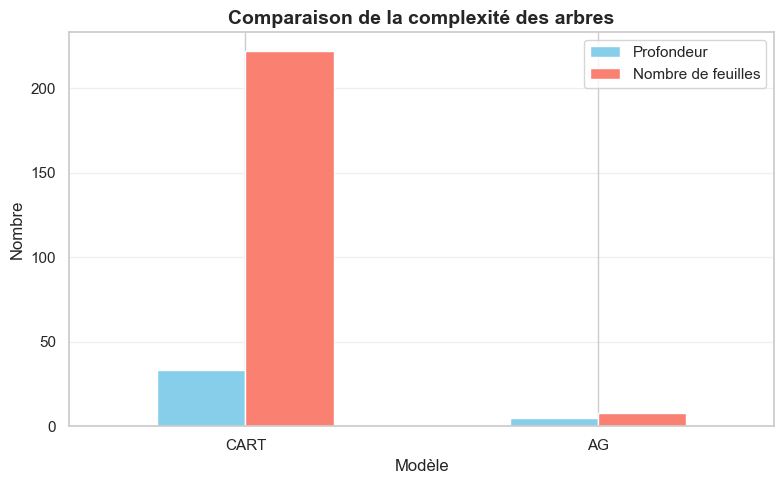

In [18]:
complexite.set_index("Modèle").plot(
    kind="bar",
    figsize=(8, 5),
    color=["skyblue", "salmon"]
)

plt.title(
    "Comparaison de la complexité des arbres",
    fontsize=14,
    fontweight="bold"
)

plt.ylabel("Nombre")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()

plt.savefig(
    "../results/graphs/complexite_arbres.png",
    dpi=150
)

plt.show()

Sauvegarde des résultats

In [19]:
# Sauvegarder le tableau de comparaison
comparaison.to_csv(
    "../results/tables/comparaison_modeles.csv",
    index=False
)

# Sauvegarder la complexité
complexite.to_csv(
    "../results/tables/complexite_arbres.csv",
    index=False
)

print("Les résultats ont été sauvegardés avec succès !")

Les résultats ont été sauvegardés avec succès !


Sauvegarder les prédictions

In [20]:
predictions = pd.DataFrame({
    "Classe réelle": y_test,
    "CART": y_pred_dt,
    "Random Forest": y_pred_rf,
    "Gradient Boosting": y_pred_gb,
    "AG": y_pred_ga
})

predictions.to_csv(
    "../results/tables/predictions_modeles.csv",
    index=False
)

print("Prédictions sauvegardées avec succès !")

Prédictions sauvegardées avec succès !


Sauvegarder l'historique de convergence

In [21]:
historique_df = pd.DataFrame({
    "Generation": range(1, len(historique) + 1),
    "Meilleure Fitness": historique
})

historique_df.to_csv(
    "../results/tables/historique_convergence.csv",
    index=False
)

print("Historique sauvegardé avec succès !")

Historique sauvegardé avec succès !


Vérification finale des fichiers

In [22]:
print(" VERIFICATION DES RESULTATS")

for dossier in [
    "../results/graphs",
    "../results/tables",
    "../results/best_tree"
]:
    print("\nDossier :", dossier)

    for fichier in os.listdir(dossier):
        print("-", fichier)

 VERIFICATION DES RESULTATS

Dossier : ../results/graphs
- .ipynb_checkpoints
- arbre_genetique.png
- comparaison_modeles.png
- complexite_arbres.png
- convergence_ag.png
- matrice_ag.png
- matrice_cart.png

Dossier : ../results/tables
- comparaison_modeles.csv
- complexite_arbres.csv
- historique_convergence.csv
- predictions_modeles.csv

Dossier : ../results/best_tree
- meilleur_arbre.pkl


Vérification des résultats

In [23]:
print("VERIFICATION FINALE ")

print("\n1. Modèles évalués :")
print(comparaison[["Modèle", "Accuracy", "Precision", "Recall", "F1-score"]].round(4))

print("\n2. Complexité des arbres :")
print(complexite)

print("\n3. Meilleur arbre génétique :")
print("Profondeur :", profondeur(meilleur_arbre))
print("Nombre de feuilles :", nombre_feuilles(meilleur_arbre))

print("\n4. Nombre de générations :", len(historique))

print("\n5. Fichiers sauvegardés avec succès.")

VERIFICATION FINALE 

1. Modèles évalués :
              Modèle  Accuracy  Precision  Recall  F1-score
0               CART    0.9990     0.7349  0.6421    0.6854
1      Random Forest    0.9995     0.9710  0.7053    0.8171
2  Gradient Boosting    0.9992     0.8676  0.6211    0.7239
3                 AG    0.9737     0.0474  0.7684    0.0892

2. Complexité des arbres :
  Modèle  Profondeur  Nombre de feuilles
0   CART          33                 222
1     AG           5                   8

3. Meilleur arbre génétique :
Profondeur : 5
Nombre de feuilles : 8

4. Nombre de générations : 10

5. Fichiers sauvegardés avec succès.


In [24]:
import pickle
import os

os.makedirs("../results/best_tree", exist_ok=True)

with open("../results/best_tree/meilleur_arbre.pkl", "wb") as fichier:
    pickle.dump(meilleur_arbre, fichier)

print("Meilleur arbre sauvegardé avec succès !")

Meilleur arbre sauvegardé avec succès !


In [25]:
print(os.listdir("../results/best_tree"))

['meilleur_arbre.pkl']


In [26]:
import sys
import os

chemin = os.path.abspath("../src/models_comparison")

if chemin not in sys.path:
    sys.path.insert(0, chemin)

from comparison import comparer_modeles, sauvegarder_comparaison

print("Import réussi !")

Import réussi !


In [27]:
modeles = [
    ("CART", dt_model, dt_time),
    ("AG", meilleur_arbre, ga_time),
    ("Random Forest", rf_model, rf_time),
    ("Gradient Boosting", gb_model, gb_time)
]

tableau = comparer_modeles(
    modeles,
    X_test,
    y_test
)

display(tableau)

,Modele,Accuracy,Precision,Recall,F1-score,Temps (s),Profondeur,Nombre de feuilles
0,CART,0.999013,0.734940,0.642105,0.685393,19.175862,33,222
1,AG,0.973743,0.047372,0.768421,0.089242,4.699825,5,8
2,Random Forest,0.999471,0.971014,0.705263,0.817073,104.386446,-,-
3,Gradient Boosting,0.999207,0.867647,0.621053,0.723926,171.560699,-,-
